In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import VBox, HBox, FloatSlider, Output, FloatLogSlider, Button, Checkbox, Layout, IntSlider
import ipywidgets as widgets
from IPython.display import display, clear_output, Audio
from scipy.interpolate import RegularGridInterpolator
import json
from scipy.special import jv

%matplotlib inline

In [2]:
todeg = 180 / np.pi
def computeZ(mp, k):
    return np.array([np.exp(np.dot(k, mp[i])*1j) for i in range(len(mp))])

def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def polar_to_look_direction(aziv, zeniv):
    return np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)

def create_look_directions(n, fov):

    fov += 1e-5
    x = np.linspace(-fov, fov, n)
    y = np.linspace(-fov, fov, n)

    xv, yv = np.meshgrid(x, y)

    # circle the square
    # ratio = np.maximum(np.abs(xv), np.abs(yv)) / (np.sqrt(xv*xv + yv*yv) + 1e-18)
    # xv *= ratio
    # yv *= ratio
    
    xv = np.reshape(xv, -1)
    yv = np.reshape(yv, -1)
    aziv = np.atan2(yv, xv)
    zeniv = np.sqrt(xv*xv + yv*yv)

    unit_look_direction = polar_to_look_direction(aziv, zeniv)
    
    # xy = np.stack((xv, yv), axis = -1)

    return (unit_look_direction, aziv, zeniv, (x, y))

def create_distance_vectors(look_directions, microphone_positions):
    return look_directions @ microphone_positions

def create_steering_vectors(distance_vectors, k):
    return np.exp(1j * distance_vectors * k)

class ArrayState:
    positions = np.array([[0, 0, 0]])
    cropac = {}
    calibration = np.array([])
    def __init__(self, pos=np.array([[0, 0, 0]]), cropac={}):
        self.positions = pos
        self.cropac = cropac

def load_array(path, calibrationPath):

    array = ArrayState()
    with open(path, "r", encoding="utf-8") as f:
        array.__dict__ = json.load(f)
    array.positions = np.stack((*np.array(array.positions).T, np.zeros(len(array.positions))))
    
    with open(calibrationPath, "r", encoding="utf-8") as f:
        array.calibration = np.array(json.load(f))

    array.positions[0] -= np.mean(array.positions[0])
    array.positions[1] -= np.mean(array.positions[1])
    
    return array

def default8():
    return load_array("default_array8_1.json", "default_array8_calibration_old.json")

def circle8():
    return load_array("circle_array8.json", "circle_array8_calibration.json")

In [3]:
# CroPaC for a planar circular array

def planar_directions(directions):
    return np.atan2(directions[:,1], directions[:,0])

def zeni_directions(directions):
    return np.atan2(np.sqrt(directions[:,0]**2 + directions[:,1]**2), directions[:,2])

def polar_to_unitdir(aziv, zeniv):
    unit_look_direction = np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)
    return unit_look_direction

def diffuse_noise_covariance(mic_array, k):
    n = mic_array.shape[1]
    dist = np.zeros((n, n), dtype=np.complex128)
    for i in range(n):
        for j in range(n):
            d = mic_array[:,i] - mic_array[:,j]
            dist[i,j] = np.sqrt(np.sum(d*d))
    return np.sinc(k * dist)

def create_cropac_weights(look_direction, look_vector, mic_array, k):

    mic = planar_directions(mic_array.T)
    dir = planar_directions(look_direction[None,:])
    relative_angles = dir[0] - mic

    m = mic_array.shape[1]
    r = np.sqrt(np.sum(mic_array[:,0] * mic_array[:,0]))

    o1 = 1
    o2 = 2

    dj_zeros = [0, 1.8411837813, 3.0542369282, 4.2011889412]

    w1_zeni = np.arcsin(min(1, dj_zeros[o1] / (k * r)))
    w2_zeni = np.arcsin(min(1, dj_zeros[o2] / (k * r)))
    look_zeni = zeni_directions(look_direction[None,:])[0]

    zeni_steer = min(1, k * r / dj_zeros[o1])**2
    zeni_steer1 = k * r * (np.sin(w1_zeni) - np.sin(look_zeni)) * zeni_steer
    zeni_steer2 = k * r * (np.sin(w2_zeni) - np.sin(look_zeni)) * zeni_steer

    kr1z = dj_zeros[o1] - zeni_steer1
    kr2z = dj_zeros[o2] - zeni_steer2
    zeni_steer2 += (kr2z - kr1z) * zeni_steer

    kr1n = min(k * r + zeni_steer1, dj_zeros[o1])
    kr2n = min(k * r + zeni_steer2, dj_zeros[o2])

    w1 = np.cos(o1 * relative_angles) * (1j**o1) / (jv(o1, kr1n)) / m
    w2 = np.cos(o2 * relative_angles) * (1j**o2) / (jv(o2, kr2n)) / m

    dv0 = create_distance_vectors(polar_to_unitdir(dir, np.array([np.pi/2])), mic_array)

    sv1 = create_steering_vectors(dv0, zeni_steer1 / r)
    sv2 = create_steering_vectors(dv0, zeni_steer2 / r)

    correction1 = np.conj(sv1)
    correction2 = np.conj(sv2)

    w1 = w1 * correction1[0]
    w2 = w2 * correction2[0]

    das_w1 = look_vector / m * 2
    das_w2 = look_vector / m * 2

    for i in range(8):
        if i&1:
            das_w2[i] = 0
        else:
            das_w1[i] = 0

    j0_zero = 2.4048
    mlw = np.arcsin(min(1, j0_zero / (k*r)))

    bstart = 45 / todeg
    bend = 30 / todeg
    mlw = min(bstart, max(mlw, bend))

    blend = (mlw - bend) / (bstart - bend)

    w1 = w1 * blend + das_w1 * (1 - blend)
    w2 = w2 * blend + das_w2 * (1 - blend)

    return w1, w2

def create_primary_weights(look_direction, look_vector, mic_array, k):

    mic = planar_directions(mic_array.T)
    dir = planar_directions(look_direction[None,:])
    relative_angles = dir[0] - mic

    m = mic_array.shape[1]
    r = np.sqrt(np.sum(mic_array[:,0] * mic_array[:,0]))

    o1 = 1

    dj_zeros = [0, 1.8411837813, 3.0542369282, 4.2011889412]

    w1_zeni = np.arcsin(min(1, dj_zeros[o1] / (k * r)))
    look_zeni = zeni_directions(look_direction[None,:])[0]

    zeni_steer = min(1, k * r / dj_zeros[o1])**2
    zeni_steer1 = k * r * (np.sin(w1_zeni) - np.sin(look_zeni)) * zeni_steer
    kr1n = min(k * r + zeni_steer1, dj_zeros[o1])
    w1 = np.cos(o1 * relative_angles) * (1j**o1) / (jv(o1, kr1n)) / m

    dv0 = create_distance_vectors(polar_to_unitdir(dir, np.array([np.pi/2])), mic_array)

    sv1 = create_steering_vectors(dv0, zeni_steer1 / r)

    correction1 = np.conj(sv1)

    w1 = w1 * correction1[0]

    das_w1 = look_vector / m * 2

    for i in range(8):
        if i&1:
            das_w1[i] = 0

    j0_zero = 2.4048
    mlw = np.arcsin(min(1, j0_zero / (k*r)))

    bstart = 45 / todeg
    bend = 30 / todeg
    mlw = min(bstart, max(mlw, bend))

    blend = (bstart - mlw) / (bstart - bend)

    w1 = w1 * (1 - blend) + das_w1 * blend

    return w1

def optimal_secondary_weights(w1, look_vector, constraints):
    
    N = w1.shape[0]
    nsdim = N - len(constraints)
    assert nsdim > 0

    constraints = [i / np.linalg.norm(i) for i in constraints]
    for i in range(N-nsdim):
        for j in range(0, i):
            constraints[i] -= (constraints[i] @ np.conj(constraints[j])) * constraints[j]
            constraints[i] /= np.linalg.norm(constraints[i])

    O = []
    for i in range(nsdim):
        basisv = np.random.randn(N).astype(np.complex128)
        basisv /= np.linalg.norm(basisv)
        for v in constraints:
            basisv -= (basisv @ np.conj(v)) * v
            basisv /= np.linalg.norm(basisv)
        constraints.append(basisv)
        O.append(basisv)

    O = np.array(O).T

    # w2 = O @ np.linalg.inv(np.conj(O).T @ O) @ np.conj(O).T @ look_vector
    w2 = O @ np.linalg.pinv(O) @ look_vector
    w2 = w2 / (np.conj(w2) @ look_vector)

    return w2 

def cropac_beampattern(w1, w2, steering_vectors):

    m = steering_vectors.shape[1]
    z1 = steering_vectors @ np.conj(w1)
    z2 = steering_vectors @ np.conj(w2)

    g = np.maximum(0, np.real(np.conj(z1) * z2))

    return z1, z2, g

In [4]:
def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def plot_mesh_planar(ax, plot_points, z):
    xv, yv = plot_points
    c = ax.pcolormesh(xv, yv, np.abs(z), shading='gouraud', cmap='viridis')
    plt.colorbar(c, ax=ax)

In [5]:


def make_array_file_widgets(get_array, set_array, default_path="circle_array8.json"):
    """
    Create widgets for saving/loading a 2D Python array.

    Parameters
    ----------
    get_array : callable
        Function returning the current 2D array.
    set_array : callable
        Function accepting a new 2D array and updating your editor/display.
    default_path : str
        Default filename/path to save to or load from.
    """

    path_box = widgets.Text(
        value=default_path,
        description="File:",
        layout=widgets.Layout(width="400px")
    )

    save_button = widgets.Button(
        description="Save array",
        button_style="success",
        icon="save"
    )

    load_button = widgets.Button(
        description="Load array",
        button_style="info",
        icon="folder-open"
    )

    status = widgets.Output()

    def save_array(_):
        with status:
            status.clear_output()
            try:
                array = get_array()
                with open(path_box.value, "w", encoding="utf-8") as f:
                    json.dump(array, f, indent=2)
                print(f"Saved array to {path_box.value}")
            except Exception as e:
                print(f"Error saving array: {e}")

    def load_array(_):
        with status:
            status.clear_output()
            try:
                with open(path_box.value, "r", encoding="utf-8") as f:
                    array = json.load(f)

                set_array(array)
                print(f"Loaded array from {path_box.value}")
            except Exception as e:
                print(f"Error loading array: {e}")

    save_button.on_click(save_array)
    load_button.on_click(load_array)

    return widgets.VBox([
        widgets.HBox([path_box, save_button, load_button]),
        status
    ]), load_array

In [ ]:
c = 344
n = 128
fig_width = 11
fov = np.pi / 2
todeg = 1 / np.pi * 180
reso = 100
MAX_CROPAC = 4
MAX_MICS = 16

adir, zdir = 0, 0
ld_udir = polar_to_look_direction(adir / todeg, zdir / todeg)

look_directions, aziv, zeniv, xy = create_look_directions(reso, fov)
plot_points = (aziv.reshape((reso, reso)),
               zeniv.reshape((reso, reso)))

w_f = FloatLogSlider(
    value=4000, base = 10, min=2, max=np.log10(6000),step=0.001,
    description="Frequency", continuous_update=True, readout_format=".1f"
)
w_idx = IntSlider(
    value=0, min=0, max=MAX_MICS, step=1,
    description="Index", continuous_update=True, readout_format=".0f"
)
w_y = FloatSlider(
    value=0, min=0, max=0.32, step=0.001,
    description="Y", continuous_update=True, readout_format=".3f"
)
w_x = FloatSlider(
    value=0, min=0, max=0.277, step=0.001,
    description="X", continuous_update=True, readout_format=".3f"
)

class State:
    array = ArrayState()
    do_update=True

state = State()

for w in (w_f, w_x, w_y):
     w.layout.width = f"{fig_width * 80 - 50}px"
    
w_idx.layout.width = f"{fig_width * 80 - 160}px"

# Low frequency CroPaC for an octagon microphone array

out = Output()
def update_plot(change=None):

    if not state.do_update:
        return

    fc = w_f.value
    pattern = np.array(state.array.positions).T
    patternX, patternY = pattern
    m = len(patternX)
    mp = np.stack((*pattern, np.zeros(m)))
    mp[0] -= np.mean(mp[0])
    mp[1] -= np.mean(mp[1])

    idx = max(0, min(int(w_idx.value), len(state.array.positions)-1))

    k = 2 * np.pi * fc / c

    ld_steer = create_steering_vectors(create_distance_vectors(np.array([ld_udir]), mp), k)[0]
    dv = create_distance_vectors(look_directions, mp)
    steering_vectors = create_steering_vectors(dv, k)

    _, ww2 = create_cropac_weights(ld_udir, ld_steer, mp, k)

    Sd = diffuse_noise_covariance(mp, k)
    w1 = create_primary_weights(ld_udir, ld_steer, mp, k)
    constraints = [(Sd + 2 * np.eye(len(w1))) @ w1]
    w2 = optimal_secondary_weights(w1, ld_steer, constraints)
    res = [*cropac_beampattern(w1, w2, steering_vectors)]

    for i in range(len(res)):
        res[i] = np.reshape(res[i], (reso, reso))
    z1, z2, g = res

    with out:
        clear_output(wait=True)

        print(np.linalg.norm(w1), np.linalg.norm(ww2), np.linalg.norm(w2))

        fig = plt.figure(figsize=(fig_width, fig_width * 0.3))
        ax4 = fig.add_subplot(1, 3, 1, projection='polar')
        ax5 = fig.add_subplot(1, 3, 2, projection='polar')
        ax6 = fig.add_subplot(1, 3, 3, projection='polar')

        plot_mesh_polar(ax6, plot_points, g)
        plot_mesh_polar(ax4, plot_points, z1)
        plot_mesh_polar(ax5, plot_points, z2)
        ax6.set_title('CroPaC gain pattern')
        ax4.set_title('CroPaC pattern U')
        ax5.set_title('CroPaC pattern V')
        plt.tight_layout()
        plt.show()

def add_mic(change=None):
    if not state.do_update:
        return
    state.array.positions.append([w_x.value, w_y.value])
    update_plot()

def delete_mic(change=None):
    if not state.do_update:
        return
    if len(state.array.positions) > 1:
        idx = max(0, min(int(w_idx.value), len(state.array.positions)-1))
        state.array.positions.pop(idx)
        update_plot()

def set_mic_position(change=None):
    if not state.do_update:
        return
    idx = max(0, min(int(w_idx.value), len(state.array.positions)-1))
    state.array.positions[idx] = [w_x.value, w_y.value]
    update_plot()

def set_idx(change=None):
    if not state.do_update:
        return
    idx = max(0, min(int(w_idx.value), len(state.array.positions)-1))
    x, y = state.array.positions[idx]
    state.do_update = False
    w_x.value = x
    w_y.value = y
    state.do_update = True
    update_plot()

def set_array(array):
    if not state.do_update:
        return
    state.array.__dict__ = array
    state.do_update = False
    
    w_idx.value = 0

    x, y = state.array.positions[0]
    w_x.value = x
    w_y.value = y
    state.do_update = True
    update_plot()

def get_array():
     return state.array.__dict__

w_x.observe(set_mic_position, names="value")
w_y.observe(set_mic_position, names="value")
w_idx.observe(set_idx, names="value")

for w in (w_f,):
    w.observe(update_plot, names="value")

afw, loadar = make_array_file_widgets(get_array, set_array)

display(VBox([
    afw,
    w_f,
    w_idx,
    w_x,
    w_y,
    out
]))


loadar(None)

<>:48: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:60: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:61: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:62: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:63: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:48: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:60: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences wil

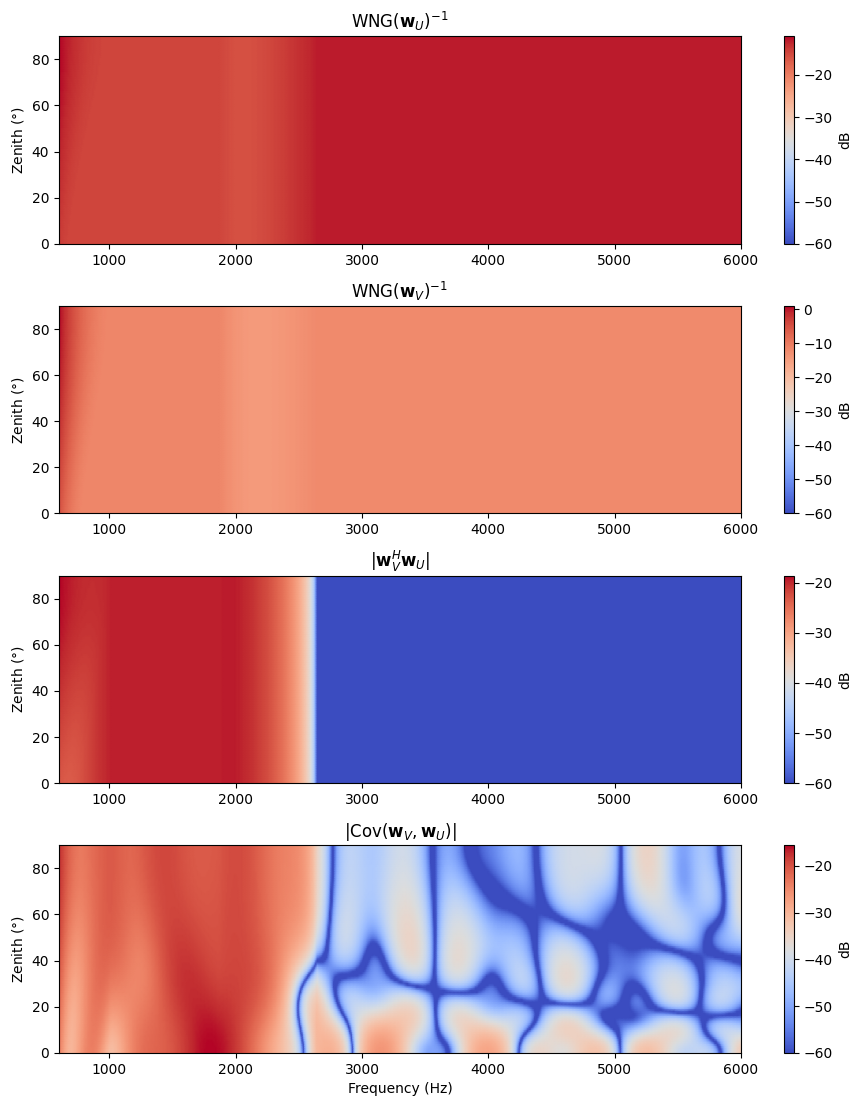

In [7]:

adir, zdir = 0, 10
f = np.linspace(600, 6000, 500)
zeni = np.linspace(0, 90, 90)

loadar(None)

pattern = np.array(state.array.positions).T
patternX, patternY = pattern
m = len(patternX)
mp = np.stack((*pattern, np.zeros(m)))
mp[0] -= np.mean(mp[0])
mp[1] -= np.mean(mp[1])

kr = 2 * np.pi * f / c

vf, vzeni = np.meshgrid(f, zeni)

w11 = np.zeros_like(vf)
w22 = np.zeros_like(vf)
w12 = np.zeros_like(vf)
cov = np.zeros_like(vf)

for i in range(len(kr)):
    for j in range(len(zeni)):

        k = kr[i]
        adir, zdir = 0, zeni[j]

        ld_udir = polar_to_look_direction(adir / todeg, zdir / todeg)
        ld_steer = create_steering_vectors(create_distance_vectors(np.array([ld_udir]), mp), k)[0]
        Sd = diffuse_noise_covariance(mp, k)

        w1, w2 = create_cropac_weights(ld_udir, ld_steer, mp, k)

        # w1 = create_primary_weights(ld_udir, ld_steer, mp, k)
        # constraints = [Sd @ w1]
        # w2 = optimal_secondary_weights(w1, ld_steer, constraints)

        w11[j,i] = np.abs(w1[None,:].conj() @ w1)[0]
        w12[j,i] = np.abs(w1[None,:].conj() @ w2)[0]
        w22[j,i] = np.abs(w2[None,:].conj() @ w2)[0]
        cov[j,i] = np.abs(w2[None,:].conj() @ Sd @ w1)[0]

def plot_mesh_planar2(ax, plot_points, z):
    xv, yv = plot_points
    c = ax.pcolormesh(xv, yv, 20 * np.log10(z + 1e-18), shading='gouraud', cmap='coolwarm')
    c.set_clim(vmin = -60)
    ax.set_ylabel("Zenith ($\degree$)")
    plt.colorbar(c, ax=ax, label='dB')
    

fig = plt.figure(figsize=(fig_width, fig_width * 1.2))
ax1 = fig.add_subplot(4, 1, 1)
ax2 = fig.add_subplot(4, 1, 2)
ax3 = fig.add_subplot(4, 1, 3)
ax4 = fig.add_subplot(4, 1, 4)

fig.subplots_adjust(hspace=0.3) 

ax1.set_title("WNG($\mathbf{w}_U$)$^{-1}$")
ax2.set_title("WNG($\mathbf{w}_V$)$^{-1}$")
ax3.set_title("|$\mathbf{w}_V^H \mathbf{w}_U|$")
ax4.set_title("|Cov($\mathbf{w}_V, \mathbf{w}_U)|$")
ax4.set_xlabel("Frequency (Hz)")

plot_mesh_planar2(ax1, (vf, vzeni), w11)
plot_mesh_planar2(ax2, (vf, vzeni), w22)
plot_mesh_planar2(ax3, (vf, vzeni), w12)
plot_mesh_planar2(ax4, (vf, vzeni), cov)